# HW4 - Anouksha Bansal

In [27]:
import json
import sys
import time
import warnings
from dataclasses import dataclass, field
from pathlib import Path

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge

HERE = Path.cwd()                      
REPO = HERE.parents[2]
sys.path.insert(0, str(REPO / "Lectures" / "modeling"))
from course_data import apply_membership, load_data, make_labels

DATABASE = REPO / "Lectures" / "modeling" / "data" / "equities_top2000.duckdb"
OUT = HERE / "outputs"
REBUILD_PANEL = True

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 160)

## 1. Get the data

* Signal dates: the last market session of each week, 2010-01 through 2026-09. Features use information up to that session's close. Entry happens at the next session's close, and the exit is the first close on or after entry + 90 calendar days. The target (`make_labels`) is aligned with exactly this entry and exit.
* Universe: `universe_membership` for the quarter of the *entry* session, including stocks that are inactive today. When a stock leaves the universe, its existing lots are kept until they mature.
* Extra screens, all known at the signal date: at least 63 complete daily returns; median 63-day dollar volume ≥ $5M; no single-day move above 100% in the last 63 sessions (to catch bad prints). That leaves about 1,700 stocks per week (range 1,360–1,928). I did not use a minimum price screen. Here `close` is split-adjusted backward from today, so a "$5 price" filter would wrongly drop stocks such as NVDA because of future splits. Dollar volume (close × volume, both split-adjusted) does not have that problem.
* Fundamentals are usable from filing date + 1 day. Ratios older than 550 days are blanked, and invalid filing lags are dropped.
* Quarantined data: the loader warned about and dropped 275 zero-price BHRB rows and 28 rows dated off the market calendar. These counts match `manifest.json`.

In [28]:
PANEL_START = "2009-12-01"     #first weekly signal kept (2010 dev rows need nothing earlier as targets)


END = "2026-09-30"             #last date in the delivery; no later prices exist or are used


BATCH = 250                    #tickers per batch keeps memory bounded on an 8 GB laptop


PRICE_FEATURES = ["mom_21", "mom_63", "mom_126", "mom_252_21", "vol_63", "drawdown_252",
                  "max_ret_21", "beta_252", "log_dollar_vol_63"]


FIN_FEATURES = ["net_margin", "operating_roa", "gross_profitability", "debt_to_assets",
                "cash_to_assets", "fcf_to_assets", "accruals_to_assets", "sales_growth_yoy"]


VALUE_FEATURES = ["log_mcap", "book_to_price", "earnings_yield", "sales_to_price"]


FEATURES = PRICE_FEATURES + FIN_FEATURES + VALUE_FEATURES + ["filing_age_days"]

In [29]:
def weekly_signal_dates(calendar):
    cal = pd.Series(pd.DatetimeIndex(calendar))
    last = cal.groupby(cal.dt.to_period("W-FRI")).max()
    return pd.DatetimeIndex(last.values)

def price_features(prices, calendar, bench_ret, keep_dates):
    frames = []
    calendar = pd.DatetimeIndex(calendar)
    for symbol, g in prices.groupby("symbol", sort=True):
        p = g.set_index("date")[["close", "adj_close", "volume"]].reindex(calendar)
        px = p.adj_close
        r = px.pct_change(fill_method=None)
        f = pd.DataFrame(index=calendar)
        f["adj_close"] = px
        f["mom_21"] = px.pct_change(21, fill_method=None)         
        f["mom_63"] = px.pct_change(63, fill_method=None)
        f["mom_126"] = px.pct_change(126, fill_method=None)
        f["mom_252_21"] = px.shift(21) / px.shift(252) - 1            
        f["vol_63"] = r.rolling(63, min_periods=63).std() * np.sqrt(252)
        f["drawdown_252"] = px / px.rolling(252, min_periods=252).max() - 1
        f["max_ret_21"] = r.rolling(21, min_periods=21).max()          
        cov = r.rolling(252, min_periods=126).cov(bench_ret)
        var = bench_ret.rolling(252, min_periods=126).var()
        f["beta_252"] = cov / var
        f["log_dollar_vol_63"] = np.log((p.close * p.volume).rolling(63, min_periods=42).median().clip(lower=1))
        f["max_abs_ret_63"] = r.abs().rolling(63, min_periods=1).max()
        f["eligible"] = px.notna() & f.vol_63.notna()               
        f["symbol"] = symbol
        f.index.name = "date"
        f = f.loc[f.index.isin(keep_dates) & px.notna()]
        frames.append(f.reset_index())
    return pd.concat(frames, ignore_index=True)

In [30]:
def load_fundamentals(database, symbols):
    with duckdb.connect(str(database), read_only=True) as con:
        f = con.execute("""SELECT symbol, fiscal_date, period, filing_date, revenue, gross_profit,
                net_income, operating_income, total_assets, total_debt, total_equity,
                cash_and_equivalents, free_cash_flow, operating_cash_flow
            FROM fundamentals WHERE fiscal_date <= ? AND symbol IN (SELECT unnest(?))""",
                        [END, list(symbols)]).fetchdf()
    for c in ["fiscal_date", "filing_date"]:
        f[c] = pd.to_datetime(f[c]).astype("datetime64[ns]")
    return f


def financial_events(fundamentals):
    f = fundamentals.loc[fundamentals.period.eq("quarter")
                         & fundamentals.filing_date.gt(fundamentals.fiscal_date)].copy()
    f["available_date"] = f.filing_date + pd.Timedelta(days=1)
    assets = f.total_assets.where(f.total_assets.gt(0))
    revenue = f.revenue.where(f.revenue.gt(0))
    f["net_margin"] = f.net_income / revenue
    f["operating_roa"] = f.operating_income / assets
    f["gross_profitability"] = f.gross_profit / assets
    f["debt_to_assets"] = f.total_debt / assets
    f["cash_to_assets"] = f.cash_and_equivalents / assets
    f["fcf_to_assets"] = f.free_cash_flow / assets
    f["accruals_to_assets"] = (f.net_income - f.operating_cash_flow) / assets
    f = f.sort_values(["symbol", "fiscal_date"])
    prior = f[["symbol", "fiscal_date", "revenue"]].rename(columns={"revenue": "revenue_ly"})
    prior["match_date"] = prior.fiscal_date + pd.Timedelta(days=365)
    f = pd.merge_asof(f.sort_values("fiscal_date"), prior.drop(columns="fiscal_date").sort_values("match_date"),
                      left_on="fiscal_date", right_on="match_date", by="symbol",
                      direction="nearest", tolerance=pd.Timedelta(days=20))
    f["sales_growth_yoy"] = f.revenue / f.revenue_ly.where(f.revenue_ly.gt(0)) - 1
    f["equity"] = f.total_equity
    f["earnings_ann"] = 4 * f.net_income
    f["revenue_ann"] = 4 * f.revenue
    cols = FIN_FEATURES + ["equity", "earnings_ann", "revenue_ann"]
    f[cols] = f[cols].replace([np.inf, -np.inf], np.nan)
    f = f.sort_values(["symbol", "available_date", "fiscal_date"])
    latest = f.groupby("symbol").fiscal_date.cummax()
    f = f.loc[f.fiscal_date.eq(latest)].drop_duplicates(["symbol", "available_date"], keep="last")
    return f[["symbol", "fiscal_date", "available_date"] + cols]


def join_financials(panel, events):
    panel = panel.sort_values("date")
    events = events.sort_values("available_date")
    out = pd.merge_asof(panel, events, left_on="date", right_on="available_date", by="symbol",
                        direction="backward")
    out["filing_age_days"] = (out.date - out.available_date).dt.days
    stale = (out.date - out.fiscal_date).dt.days.gt(550)
    out.loc[stale, FIN_FEATURES + ["equity", "earnings_ann", "revenue_ann"]] = np.nan
    assert (out.available_date.isna() | out.available_date.le(out.date)).all()
    return out


def add_value_features(panel, adj_at_selection):
    p = panel.merge(adj_at_selection, on=["symbol", "universe_selection_date"], how="left")
    mcap = p.market_cap_proxy * p.adj_close / p.adj_at_selection
    mcap = mcap.where(mcap.gt(0))
    p["log_mcap"] = np.log(mcap)
    p["book_to_price"] = p.equity / mcap
    p["earnings_yield"] = p.earnings_ann / mcap
    p["sales_to_price"] = p.revenue_ann / mcap
    p[VALUE_FEATURES] = p[VALUE_FEATURES].replace([np.inf, -np.inf], np.nan)
    return p.drop(columns=["adj_at_selection"])

In [31]:
def build(database=DATABASE):
    t0 = time.time()
    OUT.mkdir(exist_ok=True)
    with duckdb.connect(str(database), read_only=True) as con:
        symbols = con.execute("SELECT symbol FROM universe ORDER BY symbol").fetchdf().symbol.tolist()
        membership = con.execute("""SELECT symbol, quarter_start, quarter_end, selection_date,
                                    universe_rank, market_cap_proxy FROM universe_membership""").fetchdf()
        sectors = con.execute("SELECT symbol, sector FROM universe").fetchdf()
    for c in ["quarter_start", "quarter_end", "selection_date"]:
        membership[c] = pd.to_datetime(membership[c]).astype("datetime64[ns]")

    panels, wide = [], []
    calendar = None
    for i in range(0, len(symbols), BATCH):
        batch = symbols[i:i + BATCH]
        with warnings.catch_warnings(record=True) as caught:      # loader quarantines bad rows
            warnings.simplefilter("always")
            prices, _, _, bench = load_data(database, end=END, symbols=batch)
        fundamentals = load_fundamentals(database, batch)
        for w in caught:
            print(f"  batch {i // BATCH}: {w.message}")
        if calendar is None:
            calendar = pd.DatetimeIndex(bench.date)
            bench_ret = bench.set_index("date").adj_close.pct_change()
            signal_dates = weekly_signal_dates(calendar)
            signal_dates = signal_dates[signal_dates >= PANEL_START]
        pf = price_features(prices, calendar, bench_ret, signal_dates)
        pf = join_financials(pf, financial_events(fundamentals))
        pf = apply_membership(pf, membership.loc[membership.symbol.isin(batch)], calendar)
        sel = prices[["symbol", "date", "adj_close"]].rename(
            columns={"date": "universe_selection_date", "adj_close": "adj_at_selection"})
        pf = add_value_features(pf, sel)
        pf = make_labels(pf, prices, calendar)                     
        keep = ["date", "symbol", "eligible", "is_universe_member", "universe_rank", "max_abs_ret_63"] \
            + FEATURES + ["entry_date", "entry_price", "label_end", "exit_price", "target"]
        panels.append(pf[keep])
        w = prices.loc[prices.date >= "2012-06-01", ["symbol", "date", "adj_close"]]
        wide.append(w.pivot(index="date", columns="symbol", values="adj_close"))
        print(f"batch {i // BATCH + 1}/{-(-len(symbols) // BATCH)} done, {time.time() - t0:.0f}s", flush=True)

    panel = pd.concat(panels, ignore_index=True).merge(sectors, on="symbol", how="left")
    panel["sector"] = panel.sector.fillna("Unknown")
    float_cols = panel.select_dtypes("float64").columns
    panel[float_cols] = panel[float_cols].astype("float32")
    panel = panel.sort_values(["date", "symbol"]).reset_index(drop=True)
    panel.to_parquet(OUT / "panel.parquet")
    px = pd.concat(wide, axis=1).reindex(calendar[calendar >= "2012-06-01"])
    px.to_parquet(OUT / "prices_wide.parquet")
    bench[["date", "adj_close"]].to_parquet(OUT / "benchmark.parquet")
    print(f"panel {panel.shape}, prices {px.shape}, {time.time() - t0:.0f}s")

Build the panel:

In [32]:
if REBUILD_PANEL or not (OUT / "panel.parquet").exists():
    build(DATABASE)
else:
    print("Reusing existing outputs/panel.parquet")

batch 1/16 done, 4s
  batch 1: Quarantining 275 invalid adjusted-price rows; inspect the raw database and delivery audit.
batch 2/16 done, 7s
  batch 2: Quarantining 3 price rows outside the supplied market calendar; inspect the raw database and delivery audit.
batch 3/16 done, 10s
batch 4/16 done, 13s
  batch 4: Quarantining 4 price rows outside the supplied market calendar; inspect the raw database and delivery audit.
batch 5/16 done, 16s
  batch 5: Quarantining 7 price rows outside the supplied market calendar; inspect the raw database and delivery audit.
batch 6/16 done, 19s
  batch 6: Quarantining 1 price rows outside the supplied market calendar; inspect the raw database and delivery audit.
batch 7/16 done, 22s
batch 8/16 done, 26s
batch 9/16 done, 30s
  batch 9: Quarantining 2 price rows outside the supplied market calendar; inspect the raw database and delivery audit.
batch 10/16 done, 33s
  batch 10: Quarantining 2 price rows outside the supplied market calendar; inspect the r

## 2. Build and evaluate model

There are 22 candidate features. Ranks use only same-date data. Ranks also neutralize vendor outliers.

* Price: 1-, 3-, and 6-month momentum, 12-1 momentum, 63-day volatility, 252-day drawdown, maximum daily return over 21 days, 252-day beta, and log dollar volume.
* Fundamentals: net margin, operating ROA, gross profitability, debt/assets, cash/assets, FCF/assets, accruals/assets, year-over-year sales growth, and filing age.
* Size and value: a dated market cap. I take the quarter's selection cap proxy and roll it forward with the stock's own price. From it I compute log size, book/price, earnings yield (4 × quarterly NI / cap), and sales/price.

Target: the 90-day holding return minus the same-date average of screened stocks (excess return). It is clipped at the training set's 1st and 99th percentiles, with the clipping bounds learned per fit.

Chosen model (`ridge_core_ret`): Ridge regression (α = 10) on seven ranked signals: gross profitability, operating ROA, FCF/assets, earnings yield, sales/price, sales growth, and 12-1 momentum. Its output is a predicted 90-day excess return in decimal units. With ~1,700 noisy 90-day returns per week, a small linear model generalized better in development than flexible models. Gradient boosting on all features overfit signals whose effect changed from one regime to the next.

### Model code

* Tradable screen at each signal date (all known at t's close): dated universe member, 63 complete daily returns, median 63-day dollar volume ≥ $5M, no >100% one-day move in the last 63 sessions.
* Every feature becomes its same-date percentile rank minus 0.5 (median stock = 0).
* Walk-forward: at each fit date F the model trains on rows dated ≥ 2010-01-01 whose `label_end < F`, then predicts every signal in [F, next F).

In [33]:
TRAIN_START = pd.Timestamp("2010-01-01")


MIN_DOLLAR_VOL = 5e6


RANKED = ["r_" + f for f in FEATURES]

CORE = ["r_gross_profitability", "r_operating_roa", "r_fcf_to_assets", "r_earnings_yield", "r_sales_to_price", "r_sales_growth_yoy", "r_mom_252_21"]


def prepare(panel):
    p = panel.loc[panel.date.ge(TRAIN_START)
                  & panel.eligible
                  & panel.log_dollar_vol_63.ge(np.log(MIN_DOLLAR_VOL))
                  & panel.max_abs_ret_63.lt(1.0)].copy()
    g = p.groupby("date")
    for f in FEATURES:
        p["r_" + f] = (g[f].rank(pct=True) - 0.5).astype("float32")
    p["excess_target"] = p.target - g.target.transform("mean")
    p["rank_target"] = g.target.rank(pct=True) - 0.5          
    p["sector_code"] = p.sector.astype("category").cat.codes.astype("int16")
    return p.reset_index(drop=True)

In [34]:
class RankModel:
    def __init__(self, kind):
        self.kind = kind

    def _X(self, df):
        if self.kind.startswith("ridge_core"):
            return df[CORE].fillna(0.0).to_numpy()
        X = df[RANKED].fillna(0.0)                        
        if self.kind == "ridge":
            X = X.assign(fin_missing=df.r_net_margin.isna().astype(float))
            X = pd.concat([X, pd.get_dummies(df.sector_code, prefix="sec").reindex(
                columns=self.sector_cols_, fill_value=0).astype(float)], axis=1)
            return X.to_numpy()
        return np.column_stack([df[RANKED].to_numpy(), df.sector_code.to_numpy()])  

    def fit(self, df):
        if self.kind in ("momentum", "composite"):
            return self
        y = (df.rank_target if self.kind in ("ridge_core", "hgb_rank") else df.excess_target).to_numpy()
        self.clip_ = np.nanquantile(y, [0.01, 0.99])          
        y = np.clip(y, *self.clip_)
        if self.kind.startswith("ridge_core"):
            self.model_ = Ridge(alpha=10.0).fit(self._X(df), y)
        elif self.kind == "ridge":
            self.sector_cols_ = [f"sec_{c}" for c in sorted(df.sector_code.unique())]
            self.model_ = Ridge(alpha=10.0).fit(self._X(df), y)
        else:
            fast = self.kind == "hgb"
            self.model_ = HistGradientBoostingRegressor(
                learning_rate=0.05 if fast else 0.02, max_iter=200 if fast else 300, max_leaf_nodes=15, min_samples_leaf=2000,
                l2_regularization=1.0, categorical_features=[len(RANKED)], random_state=0,
                early_stopping=False).fit(self._X(df), y)
        return self

    def predict(self, df):
        if self.kind == "momentum":
            return df.r_mom_252_21.fillna(-1).to_numpy()
        if self.kind == "composite":
            return df[CORE].mean(axis=1, skipna=True).fillna(-1).to_numpy()
        return self.model_.predict(self._X(df))

In [35]:
def walk_forward(p, kind, fit_dates, end):
    out = []
    bounds = list(pd.DatetimeIndex(fit_dates)) + [pd.Timestamp(end) + pd.Timedelta(days=1)]
    for fit_date, nxt in zip(bounds[:-1], bounds[1:]):
        train = p.loc[p.date.lt(fit_date) & p.label_end.lt(fit_date) & p.target.notna()]
        assert train.label_end.max() < fit_date                   
        pred_rows = p.loc[p.date.ge(fit_date) & p.date.lt(nxt)]
        m = RankModel(kind).fit(train)
        out.append(pred_rows[["date", "symbol", "sector", "target", "excess_target", "label_end"]]
                   .assign(score=m.predict(pred_rows), fit_date=fit_date, n_train=len(train)))
        print(f"  {kind}: fit {fit_date.date()} on {len(train):,} rows -> {len(pred_rows):,} predictions",
              flush=True)
    return pd.concat(out, ignore_index=True)


def ic_table(pred, label_cutoff, top_n=50):
    v = pred.loc[pred.target.notna() & pred.label_end.le(label_cutoff)]
    ic = v.groupby("date").apply(lambda x: x.score.corr(x.target, method="spearman"),
                                 include_groups=False)
    top = v.sort_values("score", ascending=False).groupby("date").head(top_n)
    top_excess = top.groupby("date").excess_target.mean()
    return pd.Series({"weeks": len(ic), "mean_rank_IC": ic.mean(),
                      "IC_t_stat": ic.mean() / ic.std() * np.sqrt(len(ic) / 13),   
                      "pct_weeks_IC>0": (ic > 0).mean(),
                      f"top{top_n}_mean_90d_excess": top_excess.mean()})

In [36]:
class TopNStrategy:
    def __init__(self, predictions, n=50, sector_cap=0.25):
        cols = ["date", "symbol", "sector", "score"]          
        self.by_date = {d: g.sort_values("score", ascending=False)
                        for d, g in predictions[cols].groupby("date")}
        self.n, self.max_per_sector = n, max(1, int(np.floor(sector_cap * n)))

    def select(self, date):
        g = self.by_date.get(pd.Timestamp(date))
        if g is None:
            return []
        picks, counts = [], {}
        for sym, sec in zip(g.symbol, g.sector):
            if counts.get(sec, 0) >= self.max_per_sector:
                continue
            picks.append(sym)
            counts[sec] = counts.get(sec, 0) + 1
            if len(picks) == self.n:
                break
        return picks

## 3. Backtester

* $1,000,000, long only, no leverage. Three sleeves of $333k start 4 weekly signals apart. At its signal, a sleeve spends all its cash equally on the top 50 predicted stocks, with at most 12 names (25%) per sector. Each lot is held 90 calendar days and sold at the close on the maturity date, or at the next session's close if the market is shut. The sleeve then reinvests its proceeds at the next weekly signal. About a third of the portfolio turns over each month.
* One cash account. Sleeves only limit how much of it each one may spend. Every day the code asserts `cash ≥ 0` and `sum(sleeve cash) == cash`. Budgets are set at the signal close and filled at the next close, so a fill price is never known when the decision is made.
* Adjusted prices: positions are held in fractional adjusted-price units, so dividends are already included and are not added again.
* Assumptions:
  * Transaction costs: 10 bps per side on traded notional, with the entry fee included in the budget. Total fees were $95k.
  * Cash interest: cash earns 0%. Average cash was 7.4% of NAV.
  * Missing entry price: the order is cancelled and the cash is kept.
  * No quote for a held lot: the lot is marked at its last observed close and flagged as stale. A matured lot is sold at the first later close that actually exists. No fill is ever invented.
* Test window: the benchmark buys $1M of `^SP500TR` at the 2016-04-01 close. The strategy's signal is that same close and its first fills are on 2016-04-04, so the strategy sits in cash for one session. Both series are valued on 2026-09-30, including all open lots; no later prices are used.

Daily order of events on session *d*:

1. sell every lot whose maturity (entry + 90 calendar days) is ≤ *d* at *d*'s close, if *d* has a quote
   (otherwise it stays open and is retried);
2. fill the buy orders planned at the previous session's close, at *d*'s close (budget fixed at planning
   time, fee included);
3. mark all open lots (last observed quote; stale marks are counted);
4. record cash, position value and NAV;
5. if *d* is a signal date, ask the strategy for picks using information through *d*'s close and plan orders
   for the next session.

In [37]:
HOLDING_DAYS = 90

@dataclass
class Lot:
    lot_id: int
    symbol: str
    sleeve: int
    signal_date: pd.Timestamp
    entry_date: pd.Timestamp
    maturity: pd.Timestamp
    units: float
    entry_price: float
    cost: float                    
    last_price: float
    last_quote: pd.Timestamp
    stale_sessions: int = 0


@dataclass
class Order:
    symbol: str
    sleeve: int
    budget: float                  
    signal_date: pd.Timestamp


@dataclass
class BacktestResult:
    history: pd.DataFrame
    fills: pd.DataFrame
    open_lots: pd.DataFrame
    incidents: pd.DataFrame
    params: dict = field(default_factory=dict)

In [38]:
class Backtester:
    def __init__(self, prices, initial_cash=1_000_000.0, cost_bps=10.0, n_sleeves=3,
                 sleeve_stagger=4, min_sleeve_trade=1_000.0, holding_days=HOLDING_DAYS,
                 assume_cashout_after=None):
        self.prices = prices.sort_index()
        self.dates = pd.DatetimeIndex(self.prices.index)
        self.px = self.prices.to_numpy(dtype=float)      
        self.col = {s: j for j, s in enumerate(self.prices.columns)}
        self.initial_cash = float(initial_cash)
        self.cost = cost_bps / 10_000.0
        self.n_sleeves = n_sleeves
        self.sleeve_stagger = sleeve_stagger                
        self.min_sleeve_trade = min_sleeve_trade
        self.holding = pd.Timedelta(days=holding_days)
        self.assume_cashout_after = assume_cashout_after

    def quote(self, i, symbol):
        j = self.col.get(symbol)
        if j is None:
            return np.nan
        v = self.px[i, j]
        return v if np.isfinite(v) and v > 0 else np.nan

    def _check_cash(self, cash, sleeve_cash):
        assert cash >= -1e-6, f"cash went negative: {cash}"
        assert abs(cash - sum(sleeve_cash)) < 1e-4, "sleeve ledger does not match cash"

    def run(self, strategy, start, end, signal_dates):
        """strategy.select(signal_date) -> list of symbols to buy (equal weight)."""
        start, end = pd.Timestamp(start), pd.Timestamp(end)
        days = self.dates[(self.dates >= start) & (self.dates <= end)]
        first_i = self.dates.get_loc(days[0])
        signal_set = set(pd.DatetimeIndex(signal_dates))

        cash = self.initial_cash
        sleeve_cash = [self.initial_cash / self.n_sleeves] * self.n_sleeves
        lots, fills, incidents, history = [], [], [], []
        pending = []                       
        next_id, n_signals = 0, 0

        for k, d in enumerate(days):
            i = first_i + k
            still_open = []
            for lot in lots:
                if lot.maturity <= d:
                    p = self.quote(i, lot.symbol)
                    if np.isfinite(p):
                        gross = lot.units * p
                        fee = gross * self.cost
                        cash += gross - fee
                        sleeve_cash[lot.sleeve] += gross - fee
                        fills.append(dict(date=d, side="SELL", symbol=lot.symbol, lot_id=lot.lot_id,
                                          sleeve=lot.sleeve, units=lot.units, price=p, gross=gross,
                                          fee=fee, cash_change=gross - fee,
                                          pnl=gross - fee - lot.cost, entry_date=lot.entry_date,
                                          maturity=lot.maturity))
                        scheduled = self.dates[self.dates.searchsorted(lot.maturity)]
                        if d > scheduled:      
                            incidents.append(dict(date=d, symbol=lot.symbol, lot_id=lot.lot_id,
                                                  kind="late_exit",
                                                  detail=f"due {lot.maturity.date()}, first quote {d.date()}"))
                        continue
                still_open.append(lot)
            lots = still_open

            for o in pending:
                p = self.quote(i, o.symbol)
                if not np.isfinite(p):
                    incidents.append(dict(date=d, symbol=o.symbol, lot_id=None, kind="cancelled_buy",
                                          detail="no quote on fill date; cash kept"))
                    continue
                budget = min(o.budget, sleeve_cash[o.sleeve])          
                units = budget / (p * (1 + self.cost))
                fee = units * p * self.cost
                cash -= budget
                sleeve_cash[o.sleeve] -= budget
                lot = Lot(next_id, o.symbol, o.sleeve, o.signal_date, d, d + self.holding,
                          units, p, budget, p, d)
                next_id += 1
                lots.append(lot)
                fills.append(dict(date=d, side="BUY", symbol=o.symbol, lot_id=lot.lot_id, sleeve=o.sleeve,
                                  units=units, price=p, gross=units * p, fee=fee, cash_change=-budget,
                                  pnl=np.nan, entry_date=d, maturity=lot.maturity))
            pending = []
            self._check_cash(cash, sleeve_cash)

            n_stale = 0
            for lot in lots:
                p = self.quote(i, lot.symbol)
                if np.isfinite(p):
                    lot.last_price, lot.last_quote, lot.stale_sessions = p, d, 0
                else:
                    lot.stale_sessions += 1
                    n_stale += 1
                    if lot.stale_sessions == 6:     
                        incidents.append(dict(date=d, symbol=lot.symbol, lot_id=lot.lot_id,
                                              kind="stale_mark",
                                              detail=f"no quote since {lot.last_quote.date()}"))
            if self.assume_cashout_after:
                keep = []
                for lot in lots:
                    if lot.stale_sessions >= self.assume_cashout_after:
                        gross = lot.units * lot.last_price
                        fee = gross * self.cost
                        cash += gross - fee
                        sleeve_cash[lot.sleeve] += gross - fee
                        fills.append(dict(date=d, side="ASSUMED_CASHOUT", symbol=lot.symbol, lot_id=lot.lot_id,
                                          sleeve=lot.sleeve, units=lot.units, price=lot.last_price, gross=gross,
                                          fee=fee, cash_change=gross - fee, pnl=gross - fee - lot.cost,
                                          entry_date=lot.entry_date, maturity=lot.maturity))
                    else:
                        keep.append(lot)
                lots = keep
            pos_value = sum(l.units * l.last_price for l in lots)

            history.append(dict(date=d, cash=cash, positions=pos_value, nav=cash + pos_value,
                                n_lots=len(lots), n_stale=n_stale))

            if d in signal_set and k + 1 < len(days):
                nav = cash + pos_value
                for s in range(self.n_sleeves):
                    if n_signals < s * self.sleeve_stagger:
                        continue                               
                    budget = sleeve_cash[s]
                    if budget < max(self.min_sleeve_trade, 0.01 * nav / self.n_sleeves):
                        continue
                    picks = strategy.select(d)
                    if not picks:
                        continue
                    each = budget / len(picks)
                    pending += [Order(sym, s, each, d) for sym in picks]
                n_signals += 1

        hist = pd.DataFrame(history).set_index("date")
        open_lots = pd.DataFrame([vars(l) for l in lots])
        if len(open_lots):
            open_lots["value"] = open_lots.units * open_lots.last_price
        return BacktestResult(hist, pd.DataFrame(fills), open_lots, pd.DataFrame(incidents),
                              dict(cost_bps=self.cost * 1e4, n_sleeves=self.n_sleeves,
                                   start=str(days[0].date()), end=str(days[-1].date())))

In [39]:
def performance(nav, annual_rf=0.02):
    nav = nav.dropna()
    r = nav.pct_change().dropna()
    years = (nav.index[-1] - nav.index[0]).days / 365.25
    rf_daily = (1 + annual_rf) ** (1 / 252) - 1
    excess = r - rf_daily
    dd = nav / nav.cummax() - 1
    return pd.Series({
        "start": nav.index[0].date(), "end": nav.index[-1].date(),
        "initial_value": nav.iloc[0], "final_value": nav.iloc[-1],
        "total_return": nav.iloc[-1] / nav.iloc[0] - 1,
        "CAGR": (nav.iloc[-1] / nav.iloc[0]) ** (1 / years) - 1,
        "ann_volatility": r.std() * np.sqrt(252),
        "max_drawdown": dd.min(),
        "sharpe": excess.mean() / r.std() * np.sqrt(252),
    })


def benchmark_nav(bench_prices, start, end, initial=1_000_000.0):
    b = bench_prices.loc[start:end]
    return initial * b / b.iloc[0]

### Accounting checks

* The unit tests below use toy prices you can verify by hand. It checks a $1,000 lot (units = 1000/(100×1.001); proceeds = units × 110 × 0.999), weekend maturity rolling to the next session, a cancelled buy and a delayed sale when quotes are missing (NAV holds at the last mark), cash conservation across sleeves, and the metric formulas. All pass.
* Identities checked on the full test run:

| Check | Result |
|---|---|
| Start cash + Σ fill cash changes − final cash | −7.7e-9 |
| Final position value − Σ open-lot values | 9.3e-10 |
| Minimum cash balance | ≥ 0 |
| Buys / sells / lots still open | 5,900 / 5,709 / 191 |
| Shortest hold | 90 days |
| First fill | 2016-04-04 |

* Hand check against the raw price table (SPT lot): bought 2021-05-10 at 56.57 with a $10,167.32 budget, so units = 10,167.32 / (56.57 × 1.001) = 179.5504, matching the booking. Sold 2021-08-09 at 106.86, so proceeds = 179.5504 × 106.86 × 0.999 = $19,167.57, matching the booking.

**Hand-checkable unit tests** on toy prices:

In [40]:
def approx(expected, rel=1e-9, abs_=1e-6):
    class _A:
        def __eq__(self, actual):
            return np.allclose(np.asarray(actual, float), np.asarray(expected, float), rtol=rel, atol=abs_)
    return _A()


class Fixed:
    def __init__(self, picks):
        self.picks = picks

    def select(self, date):
        return list(self.picks)


def make_prices(n=140, a=None, b=None):
    dates = pd.bdate_range("2020-01-01", periods=n)
    a = np.full(n, 100.0) if a is None else a
    b = np.full(n, 50.0) if b is None else b
    return pd.DataFrame({"A": a, "B": b}, index=dates)

In [41]:
def test_single_lot_by_hand():
    px = make_prices()
    entry = px.index[1]
    exit_day = px.index[px.index.searchsorted(entry + pd.Timedelta(days=90))]
    px.loc[exit_day:, "A"] = 110.0
    bt = Backtester(px, initial_cash=1_000, cost_bps=10, n_sleeves=1, min_sleeve_trade=1)
    res = bt.run(Fixed(["A"]), px.index[0], px.index[-1], signal_dates=[px.index[0]])
    buy, sell = res.fills.iloc[0], res.fills.iloc[1]
    units = 1_000 / (100 * 1.001)
    assert buy.date == entry and buy.units == approx(units)
    assert buy.fee == approx(units * 100 * 0.001)
    assert sell.date == exit_day
    assert sell.cash_change == approx(units * 110 * 0.999)
    assert res.history.nav.iloc[0] == 1_000
    assert res.history.loc[entry, "nav"] == approx(1_000 - units * 0.1)
    assert res.history.cash.iloc[-1] == approx(units * 110 * 0.999)
    assert res.history.positions.iloc[-1] == 0


def test_exit_rolls_to_next_session_when_maturity_is_a_weekend():
    px = make_prices()
    bt = Backtester(px, initial_cash=1_000, cost_bps=0, n_sleeves=1, min_sleeve_trade=1)
    res = bt.run(Fixed(["A"]), px.index[0], px.index[-1], signal_dates=[px.index[0]])
    sell = res.fills.query("side == 'SELL'").iloc[0]
    assert sell.maturity.dayofweek >= 5 or sell.date == sell.maturity
    assert sell.date >= sell.maturity and (sell.date - sell.maturity).days <= 3

In [42]:
def test_missing_quotes_cancel_buy_and_delay_sale_without_inventing_fills():
    px = make_prices()
    px.iloc[1, px.columns.get_loc("B")] = np.nan
    bt = Backtester(px, initial_cash=1_000, cost_bps=0, n_sleeves=1, min_sleeve_trade=1)
    res = bt.run(Fixed(["A", "B"]), px.index[0], px.index[-1], signal_dates=[px.index[0]])
    assert (res.fills.side == "BUY").sum() == 1
    assert "cancelled_buy" in set(res.incidents.kind)
    assert res.history.cash.iloc[1] == approx(500)

    px2 = make_prices()
    entry = px2.index[1]
    due = px2.index[px2.index.searchsorted(entry + pd.Timedelta(days=90))]
    gap = px2.index[(px2.index >= due)][:3]
    px2.loc[gap, "A"] = np.nan
    res2 = Backtester(px2, initial_cash=1_000, cost_bps=0, n_sleeves=1, min_sleeve_trade=1).run(
        Fixed(["A"]), px2.index[0], px2.index[-1], signal_dates=[px2.index[0]])
    sell = res2.fills.query("side == 'SELL'").iloc[0]
    assert sell.date == px2.index[px2.index.searchsorted(gap[-1]) + 1]
    assert "late_exit" in set(res2.incidents.kind)
    assert res2.history.loc[gap, "nav"].eq(1_000).all()


def test_cash_never_spent_twice_with_sleeves_and_reinvestment():
    rng = np.random.default_rng(0)
    n = 400
    a = 100 * np.cumprod(1 + rng.normal(0, 0.02, n))
    b = 50 * np.cumprod(1 + rng.normal(0, 0.02, n))
    px = make_prices(n, a, b)
    bt = Backtester(px, initial_cash=1_000_000, cost_bps=10, n_sleeves=3, sleeve_stagger=4)
    signals = px.index[::5]
    res = bt.run(Fixed(["A", "B"]), px.index[0], px.index[-1], signals)
    h = res.history
    assert (h.cash >= -1e-6).all()
    assert 1_000_000 + res.fills.cash_change.sum() == approx(h.cash.iloc[-1])
    assert h.positions.iloc[-1] == approx(res.open_lots.value.sum())
    sells = res.fills.query("side == 'SELL'")
    assert ((sells.date - sells.entry_date).dt.days >= 90).all()
    first_buy = res.fills.query("side == 'BUY'").groupby("sleeve").date.min()
    assert list(first_buy.index) == [0, 1, 2] and first_buy.is_monotonic_increasing


def test_metrics_and_benchmark():
    idx = pd.bdate_range("2020-01-01", periods=253)
    nav = pd.Series(np.linspace(100, 110, 253), index=idx)
    perf = performance(nav)
    years = (idx[-1] - idx[0]).days / 365.25
    assert perf.CAGR == approx(1.1 ** (1 / years) - 1)
    assert perf.max_drawdown == 0
    dd = performance(pd.Series([100, 120, 90, 130.0], index=idx[:4]))
    assert dd.max_drawdown == approx(90 / 120 - 1)
    b = benchmark_nav(pd.Series([10, 11, 12.0], index=idx[:3]), idx[0], idx[2])
    assert list(b) == approx([1e6, 1.1e6, 1.2e6])

In [43]:
tests = [test_single_lot_by_hand, test_exit_rolls_to_next_session_when_maturity_is_a_weekend,
         test_missing_quotes_cancel_buy_and_delay_sale_without_inventing_fills,
         test_cash_never_spent_twice_with_sleeves_and_reinvestment, test_metrics_and_benchmark]
for t in tests:
    t()
    print("PASS", t.__name__)
print(f"{len(tests)} tests passed")

PASS test_single_lot_by_hand
PASS test_exit_rolls_to_next_session_when_maturity_is_a_weekend
PASS test_missing_quotes_cancel_buy_and_delay_sale_without_inventing_fills
PASS test_cash_never_spent_twice_with_sleeves_and_reinvestment
PASS test_metrics_and_benchmark
5 tests passed


## Experiment

The three stages: development (validation on 2010–2015 data only), the final test run once with the
frozen `CONFIG`, and post-test diagnostics that do not change the reported result.

In [44]:
DEV_START, DEV_END = pd.Timestamp("2013-01-01"), pd.Timestamp("2015-12-31")

TEST_START, TEST_END = pd.Timestamp("2016-04-01"), pd.Timestamp("2026-09-30")

CONFIG = dict(model="ridge_core_ret", top_n=50, sector_cap=0.25, cost_bps=10, n_sleeves=3, sleeve_stagger=4)

def load():
    panel = pd.read_parquet(OUT / "panel.parquet")
    prices = pd.read_parquet(OUT / "prices_wide.parquet")
    bench = pd.read_parquet(OUT / "benchmark.parquet").set_index("date").adj_close
    return prepare(panel), prices, bench

def first_signal_each_year(dates, years):
    dates = pd.Series(pd.DatetimeIndex(sorted(set(dates))))
    return [dates[dates.dt.year.eq(y)].min() for y in years]

### Development validation (development data only)

This is an expanding-window walk-forward. A model is fit at the first weekly signal of 2013, 2014, and 2015. It trains on rows from 2010 onward whose label had already ended (`label_end < fit date`, checked by an assertion) and predicts that year. Validation ICs use only labels that ended by 2015-12-31, so the buffer is respected. Each candidate was also run through the full backtester for 2013–2015.

I chose: Ridge, core ranks, excess-return target.

I looked at each feature's IC separately in 2010–12 and in 2013–15. Many signs flipped; for example, 6-month momentum went from −0.05 to +0.02. I kept only signals that were positive in both halves. This choice used the 2013–15 validation years, so the development numbers for the core models are optimistic. That is one reason I picked top-50 over the slightly better top-20 (more diversified, less tuned) and Ridge over the unfitted composite. Retraining rule: refit at the first test signal (2016-04-01) and then every January, on all completed labels from 2010 onward. The test period was run once with this frozen configuration.

In [45]:
def dev():
    p, prices, bench = load()
    p = p.loc[p.date.le(DEV_END)]
    fit_dates = first_signal_each_year(p.date, [2013, 2014, 2015])
    rows, curves = [], {}
    for kind in ["momentum", "composite", "ridge", "ridge_core", "ridge_core_ret", "hgb", "hgb_rank"]:
        pred = walk_forward(p, kind, fit_dates, DEV_END)
        ic = ic_table(pred, label_cutoff=DEV_END)
        for n in [20, 50]:
            signals = sorted(pred.date.unique())
            bt = Backtester(prices.loc[:DEV_END], cost_bps=CONFIG["cost_bps"], n_sleeves=3, sleeve_stagger=4)
            res = bt.run(TopNStrategy(pred, n=n), signals[0], DEV_END, signals)
            perf = performance(res.history.nav)
            rows.append({"model": kind, "top_n": n, **ic.to_dict(),
                         **perf[["CAGR", "ann_volatility", "max_drawdown", "sharpe"]].to_dict()})
            curves[f"{kind}_top{n}"] = res.history.nav
        print(rows[-1], flush=True)
    b = benchmark_nav(bench, curves["hgb_top50"].index[0], DEV_END)
    bp = performance(b)
    rows.append({"model": "^SP500TR", "top_n": None,
                 **bp[["CAGR", "ann_volatility", "max_drawdown", "sharpe"]].to_dict()})
    table = pd.DataFrame(rows)
    table.to_csv(OUT / "dev_results.csv", index=False)
    print(table.to_string(float_format=lambda x: f"{x:.4f}"))

In [46]:
dev()

  momentum: fit 2013-01-04 on 137,662 rows -> 57,519 predictions
  momentum: fit 2014-01-03 on 192,970 rows -> 66,628 predictions
  momentum: fit 2015-01-02 on 257,809 rows -> 72,995 predictions
{'model': 'momentum', 'top_n': 50, 'weeks': 143.0, 'mean_rank_IC': 0.03564618120041273, 'IC_t_stat': 0.9828633865027315, 'pct_weeks_IC>0': 0.6503496503496503, 'top50_mean_90d_excess': 0.01645416021347046, 'CAGR': 0.1734138804303309, 'ann_volatility': 0.23325407889653857, 'max_drawdown': -0.2204925280684742, 'sharpe': 0.7169577414955834}
  composite: fit 2013-01-04 on 137,662 rows -> 57,519 predictions
  composite: fit 2014-01-03 on 192,970 rows -> 66,628 predictions
  composite: fit 2015-01-02 on 257,809 rows -> 72,995 predictions
{'model': 'composite', 'top_n': 50, 'weeks': 143.0, 'mean_rank_IC': 0.062208866291311844, 'IC_t_stat': 2.8409553435800583, 'pct_weeks_IC>0': 0.8251748251748252, 'top50_mean_90d_excess': 0.019119588658213615, 'CAGR': 0.17725089534546656, 'ann_volatility': 0.15056991526

### Final test: April 1, 2016 - September 30, 2026

In [47]:
def test():
    p, prices, bench = load()
    p = p.loc[p.date.le(TEST_END)]
    signals = sorted(p.date[p.date.ge(TEST_START)].unique())
    fit_dates = [signals[0]] + first_signal_each_year(signals, range(2017, 2027))
    pred = walk_forward(p, CONFIG["model"], fit_dates, TEST_END)
    pred.to_parquet(OUT / "test_predictions.parquet")
    ic = ic_table(pred, label_cutoff=TEST_END, top_n=CONFIG["top_n"])

    bt = Backtester(prices.loc[:TEST_END], cost_bps=CONFIG["cost_bps"],
                    n_sleeves=CONFIG["n_sleeves"], sleeve_stagger=CONFIG["sleeve_stagger"])
    strat = TopNStrategy(pred, n=CONFIG["top_n"], sector_cap=CONFIG["sector_cap"])
    res = bt.run(strat, TEST_START, TEST_END, signals) 
    nav = res.history.nav
    bnav = benchmark_nav(bench, TEST_START, TEST_END)
    assert nav.index[0] == bnav.index[0] == TEST_START and nav.index[-1] == bnav.index[-1] == TEST_END

    perf = pd.DataFrame({"Strategy": performance(nav), "^SP500TR buy & hold": performance(bnav)})
    print(perf.to_string())
    print("\nOut-of-sample prediction quality:\n", ic.to_string())

    f, h = res.fills, res.history
    buys, sells = f[f.side == "BUY"], f[f.side == "SELL"]
    audit = {
        "cash_identity_error": float(1e6 + f.cash_change.sum() - h.cash.iloc[-1]),
        "nav_identity_error": float(h.positions.iloc[-1] - (res.open_lots.value.sum() if len(res.open_lots) else 0)),
        "min_cash": float(h.cash.min()),
        "n_buys": int(len(buys)), "n_sells": int(len(sells)), "open_lots_at_end": int(len(res.open_lots)),
        "min_hold_days": int((sells.date - sells.entry_date).dt.days.min()),
        "max_hold_days": int((sells.date - sells.entry_date).dt.days.max()),
        "total_fees": float(f.fee.sum()),
        "avg_cash_weight": float((h.cash / h.nav).mean()),
        "first_fill": str(buys.date.min().date()),
        "incidents": res.incidents.kind.value_counts().to_dict() if len(res.incidents) else {},
        "prediction_fit_dates": [str(d.date()) for d in fit_dates],
    }
    open_l = res.open_lots
    unresolved = open_l[(open_l.last_quote < TEST_END) | (open_l.maturity <= TEST_END)] if len(open_l) else open_l
    audit["unresolved_lot_value_at_last_mark"] = float(unresolved.value.sum()) if len(unresolved) else 0.0
    audit["final_value_if_unresolved_lots_worth_zero"] = float(nav.iloc[-1] - audit["unresolved_lot_value_at_last_mark"])
    print(json.dumps(audit, indent=2, default=str))

    lot = sells.iloc[len(sells) // 2]
    buy = buys[buys.lot_id == lot.lot_id].iloc[0]
    p_in, p_out = prices.at[buy.date, buy.symbol], prices.at[lot.date, lot.symbol]
    hand = {"symbol": lot.symbol, "entry": str(buy.date.date()), "exit": str(lot.date.date()),
            "entry_px": float(p_in), "exit_px": float(p_out), "budget": float(-buy.cash_change),
            "units_by_hand": float(-buy.cash_change / (p_in * 1.001)), "units_booked": float(buy.units),
            "proceeds_by_hand": float(buy.units * p_out * 0.999), "proceeds_booked": float(lot.cash_change)}
    print(json.dumps(hand, indent=2))

    perf.to_csv(OUT / "test_performance.csv")
    pd.DataFrame({"strategy": nav, "benchmark": bnav}).to_csv(OUT / "test_daily_nav.csv")
    res.fills.to_csv(OUT / "test_fills.csv", index=False)
    res.incidents.to_csv(OUT / "test_incidents.csv", index=False)
    res.open_lots.to_csv(OUT / "test_open_lots.csv", index=False)
    json.dump({"config": CONFIG, "ic": ic.to_dict(), "audit": audit, "hand_check": hand},
              open(OUT / "test_summary.json", "w"), indent=2, default=str)

    yearly = pd.DataFrame({"Strategy": nav, "^SP500TR": bnav}).resample("YE").last()
    yearly = yearly.pct_change().fillna(yearly.iloc[0] / 1e6 - 1)
    print("\nCalendar-year returns:\n", yearly.to_string(float_format=lambda x: f"{x:.1%}"))
    yearly.to_csv(OUT / "test_yearly_returns.csv")

    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.plot(nav.index, nav / 1e6 - 1, label=f"Strategy (core-ridge top-{CONFIG['top_n']}, 3 sleeves)", color="#1f5fa8", lw=1.6)
    ax.plot(bnav.index, bnav / 1e6 - 1, label="^SP500TR buy & hold", color="#c05a17", lw=1.6)
    ax.axhline(0, color="grey", lw=0.6)
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    ax.set_title("Cumulative return, Apr 1 2016 – Sep 30 2026 ($1M start)")
    ax.set_ylabel("Cumulative return")
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUT.parent / "cumulative_returns.png", dpi=130)
    plt.show()

  ridge_core_ret: fit 2016-04-01 on 346,193 rows -> 55,552 predictions
  ridge_core_ret: fit 2017-01-06 on 401,590 rows -> 77,604 predictions
  ridge_core_ret: fit 2018-01-05 on 477,567 rows -> 84,101 predictions
  ridge_core_ret: fit 2019-01-04 on 560,074 rows -> 85,121 predictions
  ridge_core_ret: fit 2020-01-03 on 645,124 rows -> 89,536 predictions
  ridge_core_ret: fit 2021-01-08 on 733,988 rows -> 93,107 predictions
  ridge_core_ret: fit 2022-01-07 on 825,519 rows -> 93,229 predictions
  ridge_core_ret: fit 2023-01-06 on 917,934 rows -> 92,419 predictions
  ridge_core_ret: fit 2024-01-05 on 1,009,552 rows -> 94,014 predictions
  ridge_core_ret: fit 2025-01-03 on 1,101,724 rows -> 96,509 predictions
  ridge_core_ret: fit 2026-01-02 on 1,196,310 rows -> 74,438 predictions
                     Strategy ^SP500TR buy & hold
start              2016-04-01          2016-04-01
end                2026-09-30          2026-09-30
initial_value  1,000,000.0000      1,000,000.0000
final_value  

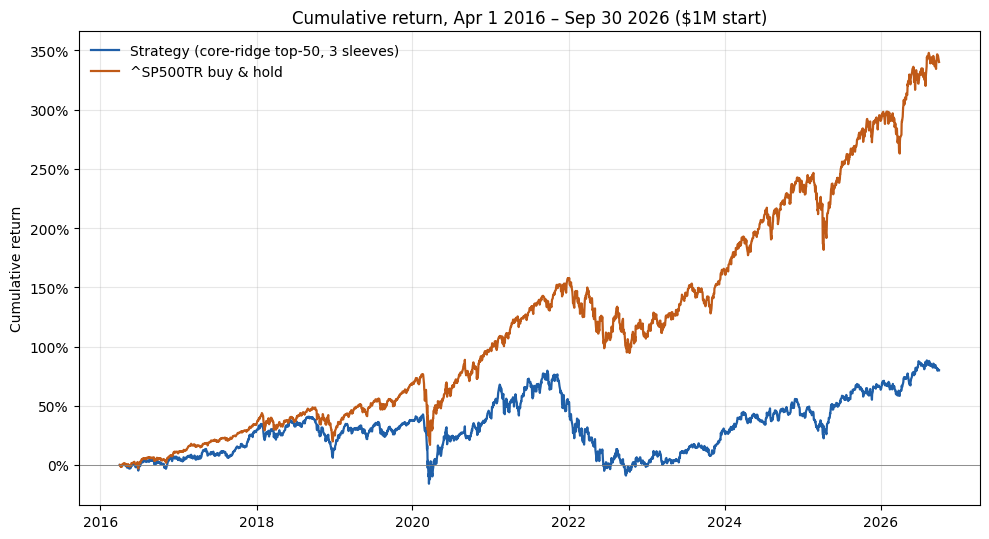

In [48]:
test()

## 4. Compare with benchmark

In [49]:
perf = pd.read_csv(OUT / "test_performance.csv", index_col=0)
s, b = perf.loc["final_value"].astype(float), perf.loc["CAGR"].astype(float)
print(f"Beat the benchmark? {s.iloc[0] > s.iloc[1]}.  Final value gap: ${s.iloc[0] - s.iloc[1]:,.0f};  "
      f"CAGR gap: {(b.iloc[0] - b.iloc[1]) * 100:.2f} percentage points per year")

Beat the benchmark? False.  Final value gap: $-2,603,528;  CAGR gap: -9.41 percentage points per year


In [50]:
lots = pd.read_csv(OUT / "test_open_lots.csv", parse_dates=["last_quote"])
(lots[lots.last_quote < "2026-09-30"]
 .groupby("symbol").agg(lots=("lot_id", "size"), last_quote=("last_quote", "max"), value=("value", "sum"))
 .sort_values("value", ascending=False))

,lots,last_quote,value
symbol,,,
REVG,3,2026-01-30,"28,639.4798"
VGR,3,2024-10-07,"27,565.8629"
WORK,2,2021-07-20,"21,301.6198"
MLHR,2,2021-10-29,"20,607.7431"
VSCO,1,2026-07-13,"19,812.5420"
TGI,2,2025-07-24,"18,942.5977"
JWN,2,2025-05-20,"17,204.1222"
HIBB,2,2024-07-25,"16,455.7663"
SPTN,2,2025-09-22,"15,456.7310"


### Post-test diagnostics

In [51]:
class EqualWeightUniverse:
    def __init__(self, pred):
        self.by_date = {d: list(g.symbol) for d, g in pred.groupby("date")}

    def select(self, date):
        return self.by_date.get(pd.Timestamp(date), [])


def diagnostics():
    _, prices, bench = load()
    pred = pd.read_parquet(OUT / "test_predictions.parquet")
    signals = sorted(pred.date.unique())
    base = dict(cost_bps=CONFIG["cost_bps"], n_sleeves=CONFIG["n_sleeves"], sleeve_stagger=CONFIG["sleeve_stagger"])
    runs = {
        "Strategy (reported)": (TopNStrategy(pred, CONFIG["top_n"], CONFIG["sector_cap"]), {}),
        "Strategy, stale lots assumed cashed out after 10 sessions": (
            TopNStrategy(pred, CONFIG["top_n"], CONFIG["sector_cap"]), {"assume_cashout_after": 10}),
        "Equal-weight screened universe, same rules": (EqualWeightUniverse(pred), {}),
        "Equal-weight universe, stale lots cashed out after 10": (EqualWeightUniverse(pred), {"assume_cashout_after": 10}),
    }
    rows, navs = {}, {}
    for name, (strat, extra) in runs.items():
        res = Backtester(prices.loc[:TEST_END], **base, **extra).run(strat, TEST_START, TEST_END, signals)
        rows[name] = performance(res.history.nav)
        rows[name]["avg_cash_weight"] = (res.history.cash / res.history.nav).mean()
        navs[name] = res.history.nav
        print(name, "done", flush=True)
    rows["^SP500TR"] = performance(benchmark_nav(bench, TEST_START, TEST_END))
    table = pd.DataFrame(rows).T[["final_value", "CAGR", "ann_volatility", "max_drawdown", "sharpe", "avg_cash_weight"]]
    table.to_csv(OUT / "diagnostics.csv")
    pd.DataFrame(navs).to_csv(OUT / "diagnostics_nav.csv")
    print(table.to_string(float_format=lambda x: f"{x:,.4f}"))

In [52]:
diagnostics()

Strategy (reported) done
Strategy, stale lots assumed cashed out after 10 sessions done
Equal-weight screened universe, same rules done
Equal-weight universe, stale lots cashed out after 10 done
                                                             final_value   CAGR ann_volatility max_drawdown sharpe avg_cash_weight
Strategy (reported)                                       1,799,219.1299 0.0575         0.2156      -0.4931 0.2768          0.0736
Strategy, stale lots assumed cashed out after 10 sessions 1,899,832.6759 0.0630         0.2300      -0.5177 0.2960          0.0783
Equal-weight screened universe, same rules                2,289,946.1664 0.0821         0.1914      -0.4057 0.4063          0.0744
Equal-weight universe, stale lots cashed out after 10     2,406,423.9092 0.0873         0.2003      -0.4101 0.4207          0.0797
^SP500TR                                                  4,402,746.7763 0.1517         0.1782      -0.3379 0.7727             NaN


## Results

| | Strategy | `^SP500TR` buy & hold |
|---|---:|---:|
| Final value (cash + open positions) | $1,799,219 | $4,402,747 |
| CAGR | 5.75% | 15.17% |
| Maximum drawdown | −49.3% | −33.8% |
| Sharpe (daily, rf = 2%/yr) | 0.28 | 0.77 |
| Annualized volatility | 21.6% | 17.8% |

I did not beat the benchmark. The strategy trailed by $2.60M. It beat the index only in 2017 (22.6% vs 21.8%) and 2023 (28.9% vs 26.3%). It lost much more in 2018 (−11% vs −4%), 2020 (+2% vs +18%), and 2022 (−34% vs −18%).

Out-of-sample prediction: mean weekly rank IC was 0.014 (t ≈ 0.8, positive in 56% of weeks). The top-50 portfolio's average 90-day excess return over the screened universe was −0.45%.

### Why:

|   | Final value | CAGR | Max DD | Sharpe |
|---|---:|---:|---:|---:|
| Strategy (reported) | $1.80M | 5.8% | −49% | 0.28 |
| Strategy, stale lots *assumed* cashed out after 10 sessions | $1.90M | 6.3% | −52% | 0.30 |
| Equal weight in **every** screened stock | $2.29M | 8.2% | −41% | 0.41 |
| `^SP500TR` | $4.40M | 15.2% | −34% | 0.77 |

1. The universe explains most of the gap (about 7 of the 9.4 points). An equal-weight mid- and small-cap portfolio badly lagged a cap-weighted index led by mega-cap tech in 2016–2026. The cap-weighted S&P 500 is a hard benchmark for any equal-weight, broad-universe stock picker.
2. The model was worse than its own universe (about −2.5 points per year). Value and quality ranks, which worked in 2010–2015, had a poor decade: value underperformed growth badly in 2018–2020, and the portfolio was crushed in the 2022 small-cap/value-trap selloff. The development IC did not survive. This partly reflects the optimistic, data-snooped feature choice described above.
3. Capital trapped in names that stopped quoting (about −0.5 points per year). 41 lots in 25 names have no quote after some date. They are mostly cash takeovers or ticker changes. The data has no delisting proceeds, so under my rule these lots stay open at their last mark. That ties up $350k at the end (19% of NAV) that is never reinvested.

### Risks taken

* An equal-weight portfolio of 150 mid- and small-cap names with a value/quality tilt. It had higher beta to small-cap and value factors than the index, which shows in 21.6% volatility and a −49% drawdown in 2020–2022.
* Sector exposure is capped at 25% of each basket, but sector labels are today's snapshot, not historical.
* Turnover is about 4× per year, at 10 bps per side.

### Main limitations

* Unresolved positions. $350k of final NAV sits in lots with no quote after maturity, valued at last mark. If those positions were worth zero, final value would be **$1.45M**. The true outcome is somewhere between (cash takeovers usually pay near the last price), but the source cannot confirm it.
* Ranking inputs: the membership table has 32 test-period rows with a cap proxy above $5T, 111 with a selection close above $100k, and 50 with more than 30B shares. For example, BRK-A shows ~$1.4 quadrillion because an A-share price is multiplied by a B-equivalent share count. These affect which stocks are in the universe, but my features use only within-date ranks.
* Selection bias: core features were chosen using 2010–2015 IC, including the validation years.

(and more)

### What I would try next

* Didn't work: Initially thought gradient boosting on all features would give me the best results, which had development IC ≈ 0 because it fit regime-specific signals. Training on the rank of the return did not help either.
* What I would try next:
  1. Pick a benchmark-aware universe.
  2. Neutralize the score to size and sector.
  3. Try to use a longer training history.